# 07 · Step 3: partial volume

A real MRI voxel near a boundary contains **several tissues**, and its intensity is a mix of
theirs. This step computes, for every output voxel, the **fraction of each label** inside it.
The same step also makes the **segmentation** that goes with the image.

Code: `nxgen/online/partial_volume.py`. Config section: `partial_volume`
(`method`, `top_k`, `smooth_sigma_vox`).

In [1]:
from _setup import *
from nxgen.online import partial_volume as PV
from nxgen.core.label_space import LabelSpace
import phantoms

tree = phantoms.tree()
seg = phantoms.sphere_labels((40, 40, 40))
ls = LabelSpace.build(tree, set(np.unique(seg).tolist()))
lab = ls.lut(int(seg.max()))[torch.as_tensor(seg)]

## 1. Two methods, one operation

Both methods compute a **weighted label histogram** in a window of HR voxels; only the window
changes:

| method | window | stride | output grid | hard label (seg) |
|---|---|---|---|---|
| `downsample` | `factor³` box, equal weights | `factor` | HR / factor | label with the largest fraction |
| `smooth` | Gaussian (std `smooth_sigma_vox`, truncated at 2 std) | 1 | HR | the HR label (unchanged) |

* `downsample` is the partial volume of the paper: the HR grid is finer than the output grid
  (here 0.2 → 0.4 mm, factor 2), and each output voxel is made of `factor³` HR voxels.
* `smooth` is for `factor = 1` (HR grid = output grid): voxels near a boundary get a mix of the
  labels around them.

In [2]:
for method, f, s in [('downsample', 2, 0), ('downsample', 4, 0), ('smooth', 1, 0.5), ('smooth', 1, .7), ('smooth', 1, 1.0)]:
    size, stride, g = PV.window(method, f, s)
    print(f'{method:10s} factor {f} sigma {s}: window {size}^3 = {size**3} voxels, stride {stride}, '
          f'first weights {[round(float(v), 4) for v in g[:5]]}...')

downsample factor 2 sigma 0: window 2^3 = 8 voxels, stride 2, first weights [0.125, 0.125, 0.125, 0.125, 0.125]...
downsample factor 4 sigma 0: window 4^3 = 64 voxels, stride 4, first weights [0.0156, 0.0156, 0.0156, 0.0156, 0.0156]...
smooth     factor 1 sigma 0.5: window 3^3 = 27 voxels, stride 1, first weights [0.0012, 0.0089, 0.0012, 0.0089, 0.066]...
smooth     factor 1 sigma 0.7: window 5^3 = 125 voxels, stride 1, first weights [0.0, 0.0, 0.0001, 0.0, 0.0]...
smooth     factor 1 sigma 1.0: window 5^3 = 125 voxels, stride 1, first weights [0.0002, 0.0007, 0.0012, 0.0007, 0.0002]...


## 2. Output: sparse top-k

Storing one fraction per label per voxel does not fit in memory for NextBrain:

In [3]:
voxels = 239 * 439 * 289                                 # case-1 at 0.4 mm
print('dense fractions  :', gb(voxels * 300 * 4), '(300 labels, float32)')
print('top-8 (int16 + float32):', gb(voxels * 8 * (2 + 4)))

dense fractions  : 36.39 GB (300 labels, float32)
top-8 (int16 + float32): 1.46 GB


So each voxel keeps only its `top_k` largest fractions:

| output | shape | meaning |
|---|---|---|
| `index` | (k, X, Y, Z) int16 | label indices, largest fraction first (0 where the weight is 0) |
| `weight` | (k, X, Y, Z) float32 | fractions, renormalised to sum to 1 |
| `seg` | (X, Y, Z) int16 | hard segmentation |
| `lost` | (X, Y, Z) float32 | fraction dropped by the truncation |

With `downsample`, `k = factor³` is exact (a voxel cannot contain more labels than HR voxels),
so `top_k = 8` is exact for factor 2. Hard labels are the case `k = 1`.

In [4]:
pv = PV.apply(lab, 'downsample', factor=2, top_k=8)
for k, v in pv.items():
    print(f'{k:6s} {tuple(v.shape)} {v.dtype}')
x, y, z = 10, 3, 10
print('\na boundary voxel:', [(ls.names[int(i)], round(float(w), 3))
                              for i, w in zip(pv['index'][:, x, y, z], pv['weight'][:, x, y, z]) if w > 0])

index  (8, 20, 20, 20) torch.int16
weight (8, 20, 20, 20) torch.float32
seg    (20, 20, 20) torch.int16
lost   (20, 20, 20) torch.float32

a boundary voxel: [('background', 0.5), ('csf', 0.5)]


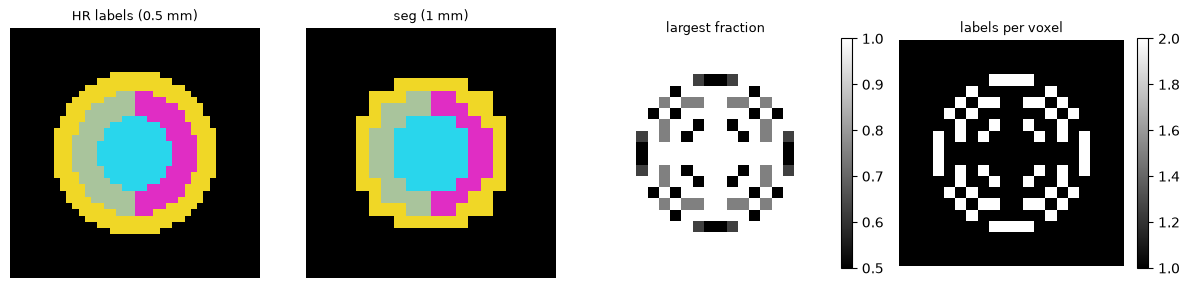

In [5]:
show([lab, pv['seg'], pv['weight'][0], (pv['weight'] > 0).sum(0)],
     ['HR labels (0.5 mm)', 'seg (1 mm)', 'largest fraction', 'labels per voxel'],
     labels=[True, True, False, False], colorbar=True)

Interior voxels are pure (largest fraction = 1, one label); boundary voxels mix 2-3 labels.

## 3. How the histogram is computed

A naive histogram needs one counter per label per voxel (K-sized arrays). Instead, for the `W`
labels `L_1..L_W` of a window with weights `g_1..g_W`:

$$\text{weight}(i) = \sum_j g_j\,[L_j = L_i]$$

is the total weight of the label of entry `i`. Entries that repeat an earlier label are set to 0,
and the `k` largest are kept. The cost depends on the window size (W² comparisons per voxel), not
on the number of labels, and the work is done in slabs to bound memory (`budget_bytes`).

**Ties** (e.g. 4 + 4 of 8 voxels) go to the smallest index, as in v2. The result is checked
against a brute-force one-hot count in the tests:

In [6]:
blk = lab.long().view(20, 2, 20, 2, 20, 2).permute(0, 2, 4, 1, 3, 5)
counts = torch.nn.functional.one_hot(blk.reshape(20, 20, 20, 8), len(ls)).sum(3)
print('seg == brute-force majority (ties -> smallest index):', torch.equal(pv['seg'].long(), counts.argmax(-1)))
mass = [(pv['weight'] * (pv['index'] == i)).sum().item() for i in range(len(ls))]
print('mass of each label == HR voxels / 8:', np.allclose(mass, [(lab == i).sum().item() / 8 for i in range(len(ls))]))

seg == brute-force majority (ties -> smallest index): True
mass of each label == HR voxels / 8: True


## 4. Truncation: `top_k` smaller than needed

With `top_k = 1` every voxel is hard-labelled and the dropped fraction is reported in `lost`:

In [7]:
pv1 = PV.apply(lab, 'downsample', factor=2, top_k=1)
pv2 = PV.apply(lab, 'downsample', factor=2, top_k=2)
print('top_k=1: max lost', float(pv1['lost'].max()), '| voxels with lost > 0:', int((pv1['lost'] > 0).sum()))
print('top_k=2: max lost', float(pv2['lost'].max()), '| voxels with lost > 0:', int((pv2['lost'] > 0).sum()))
print('top_k=8: max lost', float(pv['lost'].max()))

top_k=1: max lost 0.5 | voxels with lost > 0: 728
top_k=2: max lost 0.0 | voxels with lost > 0: 0
top_k=8: max lost 0.0


## 5. The `smooth` method

seg unchanged: True


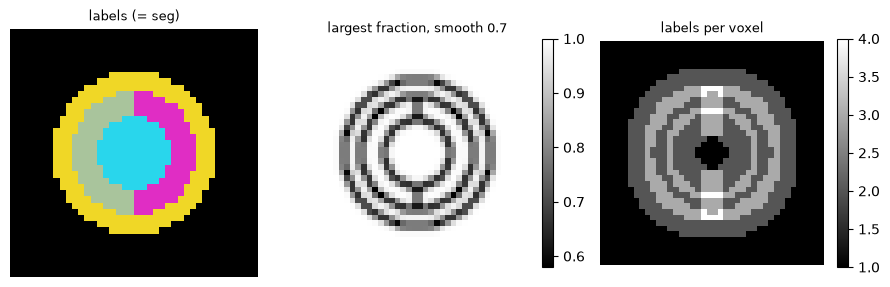

In [8]:
pvs = PV.apply(lab, 'smooth', factor=1, top_k=4, sigma_vox=0.7)
print('seg unchanged:', torch.equal(pvs['seg'], lab))
show([lab, pvs['weight'][0], (pvs['weight'] > 0).sum(0)],
     ['labels (= seg)', 'largest fraction, smooth 0.7', 'labels per voxel'],
     labels=[True, False, False], colorbar=True)

The `smooth_sigma_vox` value is a choice (there is no paper prior for it): it sets how wide the
mixed band around each boundary is.

## 6. On the real template

### Using downsampling

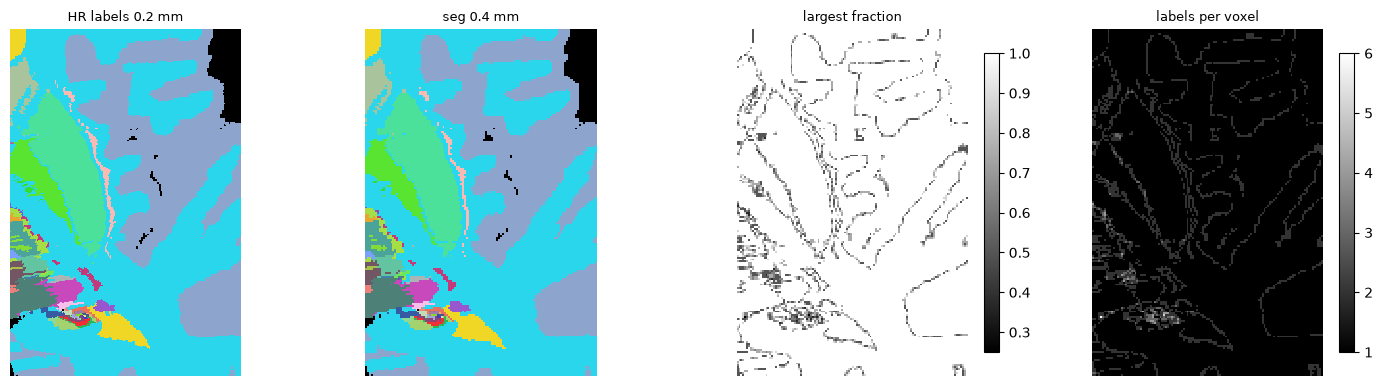

pure voxels (one label): 94.9% of the volume


In [10]:
from nxgen import Generator, Recorder
from nxgen.core.config import load_config
ensure_template()
gen = Generator([TEMPLATE], CONFIG, device=DEVICE)
rec = Recorder(steps=['spatial', 'pv_seg', 'pv_max', 'pv_count'])
s = gen(0, recorder=rec)
crop = (slice(60, 180), slice(150, 330))
hr_crop = (slice(120, 360), slice(300, 660))
z = s.seg.shape[2] // 2
show([rec.steps['spatial'][:, :, 2 * z][hr_crop], rec.steps['pv_seg'][:, :, z][crop],
      rec.steps['pv_max'][:, :, z][crop], rec.steps['pv_count'][:, :, z][crop]],
     ['HR labels 0.2 mm', 'seg 0.4 mm', 'largest fraction', 'labels per voxel'],
     labels=[True, True, False, False], size=3.6, colorbar=True)
w = rec.steps['pv_max']
print(f'pure voxels (one label): {float((w > 1 - 1e-6).float().mean()):.1%} of the volume')

### Using gaussina smoothing

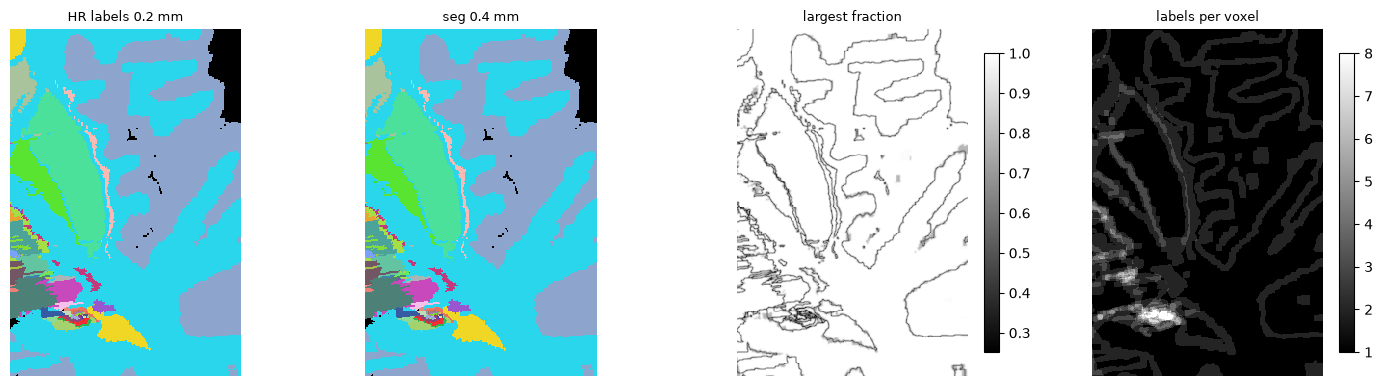

pure voxels (one label): 85.5% of the volume


In [16]:
from nxgen import Generator, Recorder
from nxgen.core.config import load_config
ensure_template()
_config = load_config(CONFIG)
_config['grid']['target_voxel_mm'] = _config['template']['hr_voxel_mm']
_config['partial_volume'] = {'method': 'smooth', 'factor': 1, 'top_k': 8, 'smooth_sigma_vox': 0.7}

gen = Generator([TEMPLATE], _config, device=DEVICE)
rec = Recorder(steps=['spatial', 'pv_seg', 'pv_max', 'pv_count'])
s = gen(0, recorder=rec)
hr_crop = (slice(120, 360), slice(300, 660))
z = s.seg.shape[2] // 2
show([rec.steps['spatial'][:, :,  z][hr_crop], rec.steps['pv_seg'][:, :, z][hr_crop],
      rec.steps['pv_max'][:, :, z][hr_crop], rec.steps['pv_count'][:, :, z][hr_crop]],
     ['HR labels 0.2 mm', 'seg 0.4 mm', 'largest fraction', 'labels per voxel'],
     labels=[True, True, False, False], size=3.6, colorbar=True)
w = rec.steps['pv_max']
print(f'pure voxels (one label): {float((w > 1 - 1e-6).float().mean()):.1%} of the volume')

## 7. Notes

* The segmentation is made here and **never degraded** afterwards: it stays sharp on the output
  grid whatever the simulated acquisition (SynthSeg, Sec. 3.1.5).
* Memory/time on the full 0.4 mm `case-1`: 0.18 s and ~3 GB.
* Partial volumes are computed per **label**. Step 4 then groups labels into generation classes
  (notebook 08).